# General queries

The .csv files were generated simply by querying pubmed and downloading the summary .csv from the pubmed web portal.

In [1]:
import os
import pandas as pd

# Set the correct directory

# Normalize filenames to avoid issues with spaces
csv_files = [f.strip() for f in os.listdir("./pubmed") if f.endswith(".csv")]

for csv_file in csv_files:
    file_path = os.path.abspath(os.path.join("./pubmed", csv_file))
    
    print(f"\n===== {csv_file} =====")
    
    df = pd.read_csv(file_path)
    print(df.head())  # Print the first 5 lines



===== PubMed_Timeline_Results_by_Year (9).csv =====
     Search query: "CUT&RUN" OR "CUT&TAG"
Year                                Count
2025                                   72
2024                                  272
2023                                  157
2022                                  103

===== PubMed_Timeline_Results_by_Year (5).csv =====
     Search query: "ChIP-seq"
Year                    Count
2025                      138
2024                      680
2023                      666
2022                      688

===== PubMed_Timeline_Results_by_Year (4).csv =====
     Search query: "Single-cell sequencing"
Year                                  Count
2025                                    372
2024                                   1578
2023                                   1105
2022                                    941

===== PubMed_Timeline_Results_by_Year (8).csv =====
     Search query: "DNase-seq" OR "DNAse-seq" OR "DHS-seq"
Year                             

In [2]:
import os
import glob
import pandas as pd

input_dir = "./pubmed"
data = {}

rename_dict = {
    "RRBS": "RRBS",
    "genome": "Genome",
    "WGBS": "WGBS",
    "WGS": "WGS",
    "DNase-seq OR DNAse-seq OR DHS-seq": "DNase-seq",
    "dnase-seq": "DNase-seq",
    "Microarray OR Microarrays": "Microarray",
    "Hi-C OR Chromosome conformation capture": "Hi-C",
    "mnase-seq": "MNase-seq",
    "single-cell sequencing": "Single-cell sequencing",
    "single-cell": "Single-cell",
    "ATAC-seq chromatin": "ATAC-seq",
    "sequencing": "Sequencing",
    "ChIP-seq": "ChIP-seq",
    "chip-on-chip": "ChIP-on-chip",
    "sanger sequencing": "Sanger sequencing",
    "RNA-seq": "RNA-seq",
    "Bisulfite sequencing OR RRBS OR WGBS": "Bisulfite sequencing",
    "CUT&RUN OR CUT&TAG": "CUTnRUN + CUTnTAG",
}

# Process each CSV file
for file in glob.glob(os.path.join(input_dir, "*.csv")):
    if file.endswith("merged.csv"):
        continue

    with open(file, "r", encoding="utf-8") as f:
        # Extract search query from the first line
        query_line = f.readline().strip()
        search_query = query_line.split(":")[1].strip().replace('"', "")

    # Standardize the search query name using rename_dict
    search_query = rename_dict.get(search_query, search_query)

    # Read CSV, skipping the first row
    df = pd.read_csv(file, skiprows=1)

    # Store in dictionary
    data[search_query] = df.set_index("Year")["Count"]

# Create merged DataFrame
merged_df = pd.DataFrame(data).sort_index(ascending=False)

# Save to CSV
merged_output_file = os.path.join(input_dir, "pubmed_merged.csv")
merged_df.to_csv(merged_output_file)

print(f"Successfully merged and saved to {merged_output_file}")


Successfully merged and saved to ./pubmed/pubmed_merged.csv


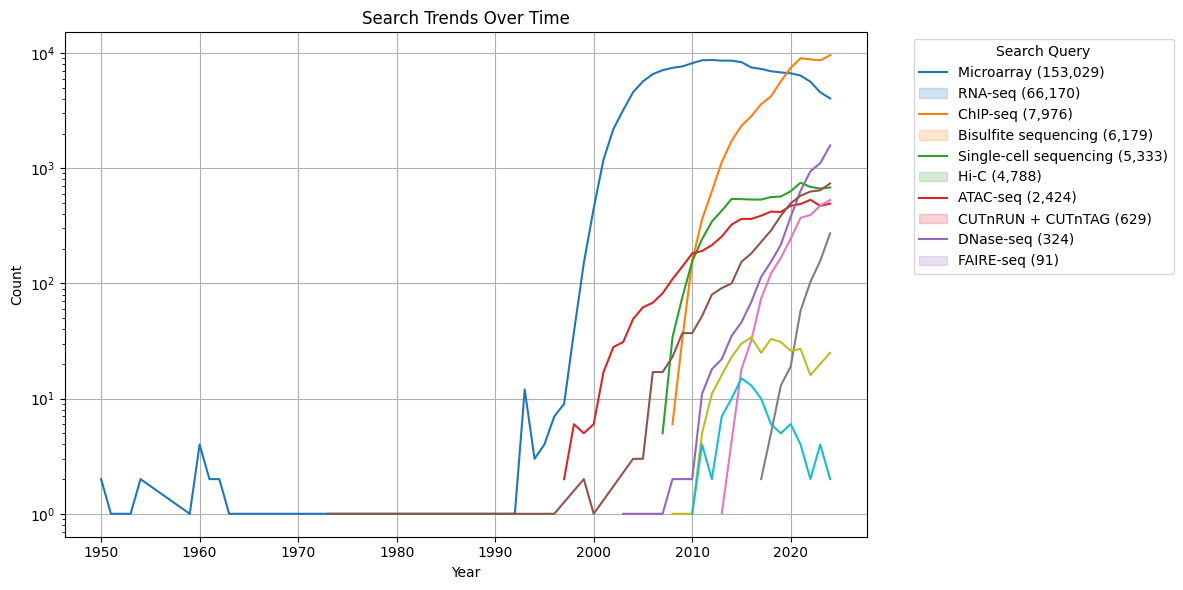

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

input_dir = "./pubmed"
merged_output_file = os.path.join(input_dir, "pubmed_merged.csv")
df = pd.read_csv(merged_output_file)

df_long = df.melt(id_vars="Year", var_name="Search Query", value_name="Count")
df_long["Year"] = df_long["Year"].astype(int)
df_long = df_long[(df_long["Year"] >= 1925) & (df_long["Year"] < 2025)]

total_counts = (
    df_long.groupby("Search Query")["Count"].sum().sort_values(ascending=False)
)
order = total_counts.index.tolist()
labels = [f"{query} ({int(total_counts[query]):,})" for query in order]

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_long, x="Year", y="Count", hue="Search Query", hue_order=order)
plt.yscale("log")
plt.xlabel("Year")
plt.ylabel("Count")
plt.title("Search Trends Over Time")
plt.legend(
    title="Search Query", bbox_to_anchor=(1.05, 1), loc="upper left", labels=labels
)
plt.grid(True)
plt.tight_layout()
plt.show()

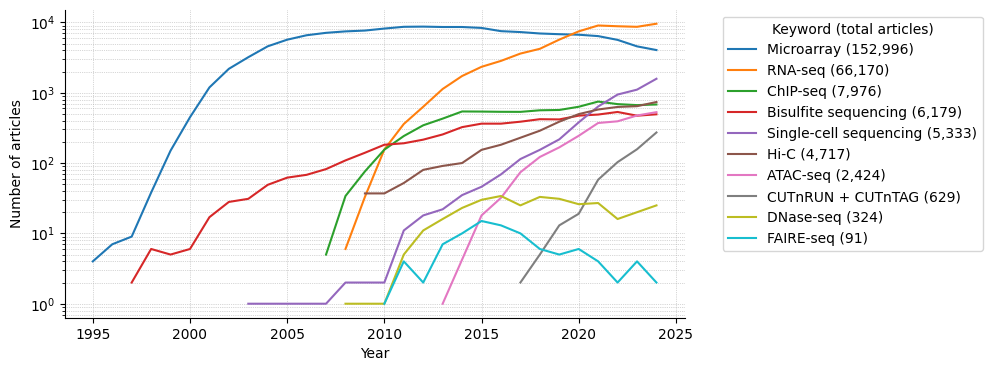

In [5]:
import numpy as np

input_dir = "./pubmed"
merged_output_file = os.path.join(input_dir, "pubmed_merged.csv")
df = pd.read_csv(merged_output_file).set_index("Year")

df.index = df.index.astype(int)
df = df.reset_index()

df_long = df.melt(id_vars="Year", var_name="Search Query", value_name="Count")

df_long = df_long[(df_long["Year"] >= 1995) & (df_long["Year"] < 2025)]
df_long.loc[(df_long["Search Query"] == "Hi-C") & (df_long["Year"] < 2009), "Count"] = (
    np.nan
)

total_counts = (
    df_long.groupby("Search Query")["Count"].sum().sort_values(ascending=False)
)


df_long["Search Query"] = df_long["Search Query"].map(
    lambda x: f"{x} ({int(total_counts[x]):,})"
)

order = total_counts.index.tolist()

plt.figure(figsize=(8, 4))
sns.lineplot(
    data=df_long,
    x="Year",
    y="Count",
    hue="Search Query",
    hue_order=[f"{q} ({int(total_counts[q]):,})" for q in order],
)

plt.yscale("log")

plt.xlabel("Year")
plt.ylabel("Number of articles")
plt.legend(title="Keyword (total articles)", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, which="both", linestyle="dotted", linewidth=0.5)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

# plt.tight_layout()
plt.show()


findfont: Font family ['serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern Roman


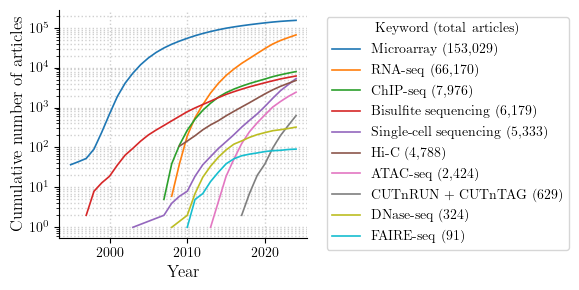

In [6]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib

# Use LaTeX font settings to match pgfplots
matplotlib.rcParams.update(
    {
        "text.usetex": True,  # Enable LaTeX rendering
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman"],  # Same as pgfplots default
        "axes.labelsize": 12,
        "axes.titlesize": 12,
        "legend.fontsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "grid.alpha": 0.6,  # Lighter grid lines
        "axes.grid": True,  # Enable grid like pgfplots
        "lines.linewidth": 1.2,  # Match pgfplots default thickness
        "lines.markeredgewidth": 0.5,  # Thinner edges on markers
    }
)


input_dir = "./pubmed"
merged_output_file = os.path.join(input_dir, "pubmed_merged.csv")
df = pd.read_csv(merged_output_file).set_index("Year")

df.index = df.index.astype(int)
df = df.reset_index()

# Ensure "Year" is in ascending order before applying cumulative sum
df = df.sort_values("Year")

# Apply cumulative sum except for "Year"
df.iloc[:, 1:] = df.iloc[:, 1:].cumsum()

df_long = df.melt(id_vars="Year", var_name="Search Query", value_name="Count")

df_long = df_long[(df_long["Year"] >= 1995) & (df_long["Year"] < 2025)]
df_long.loc[(df_long["Search Query"] == "Hi-C") & (df_long["Year"] < 2009), "Count"] = (
    np.nan
)

# Compute total cumulative counts
total_counts = (
    df_long.groupby("Search Query")["Count"].max().sort_values(ascending=False)
)

df_long["Search Query"] = df_long["Search Query"].map(
    lambda x: f"{x} ({int(total_counts[x]):,})"
)

order = total_counts.index.tolist()

plt.figure(figsize=(6, 3))
sns.lineplot(
    data=df_long,
    x="Year",
    y="Count",
    hue="Search Query",
    hue_order=[f"{q} ({int(total_counts[q]):,})" for q in order],
)

plt.yscale("log")

plt.xlabel("Year")
plt.ylabel("Cumulative number of articles")
plt.legend(title="Keyword (total articles)", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, which="both", linestyle="dotted", linewidth=1)
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("plot_pubmed.svg", format="svg")
plt.savefig("plot_pubmed.png")
plt.savefig("plot_pubmed.pgf")
plt.show()


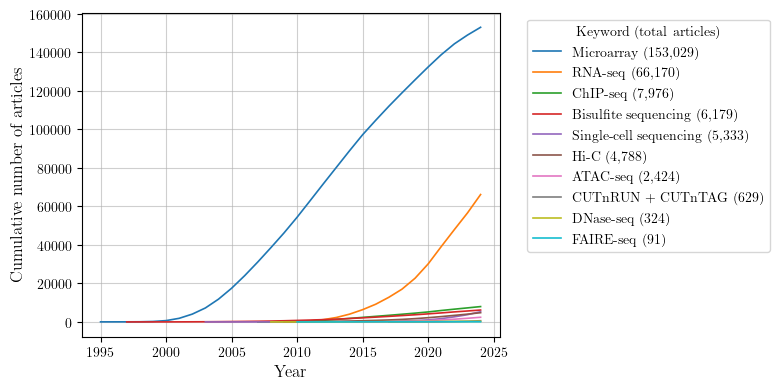

In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

input_dir = "./pubmed"
merged_output_file = os.path.join(input_dir, "pubmed_merged.csv")
df = pd.read_csv(merged_output_file).set_index("Year")

df.index = df.index.astype(int)
df = df.reset_index()

# Ensure "Year" is in ascending order before applying cumulative sum
df = df.sort_values("Year")

# Apply cumulative sum except for "Year"
df.iloc[:, 1:] = df.iloc[:, 1:].cumsum()

df_long = df.melt(id_vars="Year", var_name="Search Query", value_name="Count")

df_long = df_long[(df_long["Year"] >= 1995) & (df_long["Year"] < 2025)]
df_long.loc[(df_long["Search Query"] == "Hi-C") & (df_long["Year"] < 2009), "Count"] = (
    np.nan
)

total_counts = (
    df_long.groupby("Search Query")["Count"].max().sort_values(ascending=False)
)

df_long["Search Query"] = df_long["Search Query"].map(
    lambda x: f"{x} ({int(total_counts[x]):,})"
)

order = total_counts.index.tolist()

plt.figure(figsize=(8, 4))
sns.lineplot(
    data=df_long,
    x="Year",
    y="Count",
    hue="Search Query",
    hue_order=[f"{q} ({int(total_counts[q]):,})" for q in order],
)

# plt.yscale("log")

plt.xlabel("Year")
plt.ylabel("Cumulative number of articles")
plt.legend(title="Keyword (total articles)", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)

plt.tight_layout()
plt.show()
